In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Data analysis and visualization of last 30 days

In [2]:
df30 = pd.read_csv('cleaned_bagdolLast30days.csv')
df30

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6230465,Bagdol,temperature,25.0,c,2026-09-12 06:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-09-12,06:45:00
1,6230465,Bagdol,temperature,25.2,c,2026-09-12 07:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-09-12,07:45:00
2,6230465,Bagdol,temperature,28.9,c,2026-09-12 08:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-09-12,08:45:00
3,6230465,Bagdol,temperature,30.5,c,2026-09-12 09:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-09-12,09:45:00
4,6230465,Bagdol,temperature,30.5,c,2026-09-12 10:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-09-12,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
714,6230465,Bagdol,temperature,22.5,c,2026-10-12 01:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-12,01:45:00
715,6230465,Bagdol,temperature,22.3,c,2026-10-12 02:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-12,02:45:00
716,6230465,Bagdol,temperature,22.0,c,2026-10-12 03:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-12,03:45:00
717,6230465,Bagdol,temperature,21.3,c,2026-10-12 04:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-12,04:45:00


In [3]:
df30.info()

<class 'pandas.DataFrame'>
RangeIndex: 719 entries, 0 to 718
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   location_id    719 non-null    int64  
 1   location_name  719 non-null    str    
 2   parameter      719 non-null    str    
 3   value          719 non-null    float64
 4   unit           719 non-null    str    
 5   datetimeLocal  719 non-null    str    
 6   timezone       719 non-null    str    
 7   latitude       719 non-null    float64
 8   longitude      719 non-null    float64
 9   owner_name     719 non-null    str    
 10  provider       719 non-null    str    
 11  date           719 non-null    str    
 12  time           719 non-null    str    
dtypes: float64(3), int64(1), str(9)
memory usage: 136.3 KB


In [4]:
# Convert the date column to a proper datetime value
df30["date"] = pd.to_datetime(df30["date"])

# Group records by date and calculate the daily mean temperature
daily_mean = (
    df30.groupby("date", as_index=False)
      .agg(
          daily_mean_value=("value", "mean"),
          observation_count=("value", "count"),
          location_id=("location_id", "first"),
          location_name=("location_name", "first"),
          parameter=("parameter", "first"),
          unit=("unit", "first"),
          timezone=("timezone", "first"),
          latitude=("latitude", "first"),
          longitude=("longitude", "first"),
          owner_name=("owner_name", "first"),
          provider=("provider", "first"),
      )
)

# Arrange columns in a clear order
daily_mean = daily_mean[
    [
        "date", "location_id", "location_name", "parameter",
        "daily_mean_value", "unit", "observation_count",
        "timezone", "latitude", "longitude", "owner_name", "provider",
    ]
]

# Save the daily averages
# daily_mean.to_csv("bagdol_daily_mean_temperature.csv", index=False)

In [5]:
daily_mean

,date,location_id,location_name,parameter,daily_mean_value,unit,observation_count,timezone,latitude,longitude,owner_name,provider
0,2026-09-12,6230465,Bagdol,temperature,28.511111,c,18,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient
1,2026-09-13,6230465,Bagdol,temperature,27.391667,c,24,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient
2,2026-09-14,6230465,Bagdol,temperature,27.433333,c,24,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient
3,2026-09-15,6230465,Bagdol,temperature,27.175000,c,24,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient
4,2026-09-16,6230465,Bagdol,temperature,27.812500,c,24,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient
5,2026-09-17,6230465,Bagdol,temperature,27.450000,c,24,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient
6,2026-09-18,6230465,Bagdol,temperature,26.608333,c,24,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient
7,2026-09-19,6230465,Bagdol,temperature,26.665217,c,23,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient
8,2026-09-20,6230465,Bagdol,temperature,27.466667,c,24,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient
9,2026-09-21,6230465,Bagdol,temperature,26.804167,c,24,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient


/tmp/ipykernel_10995/3570141088.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


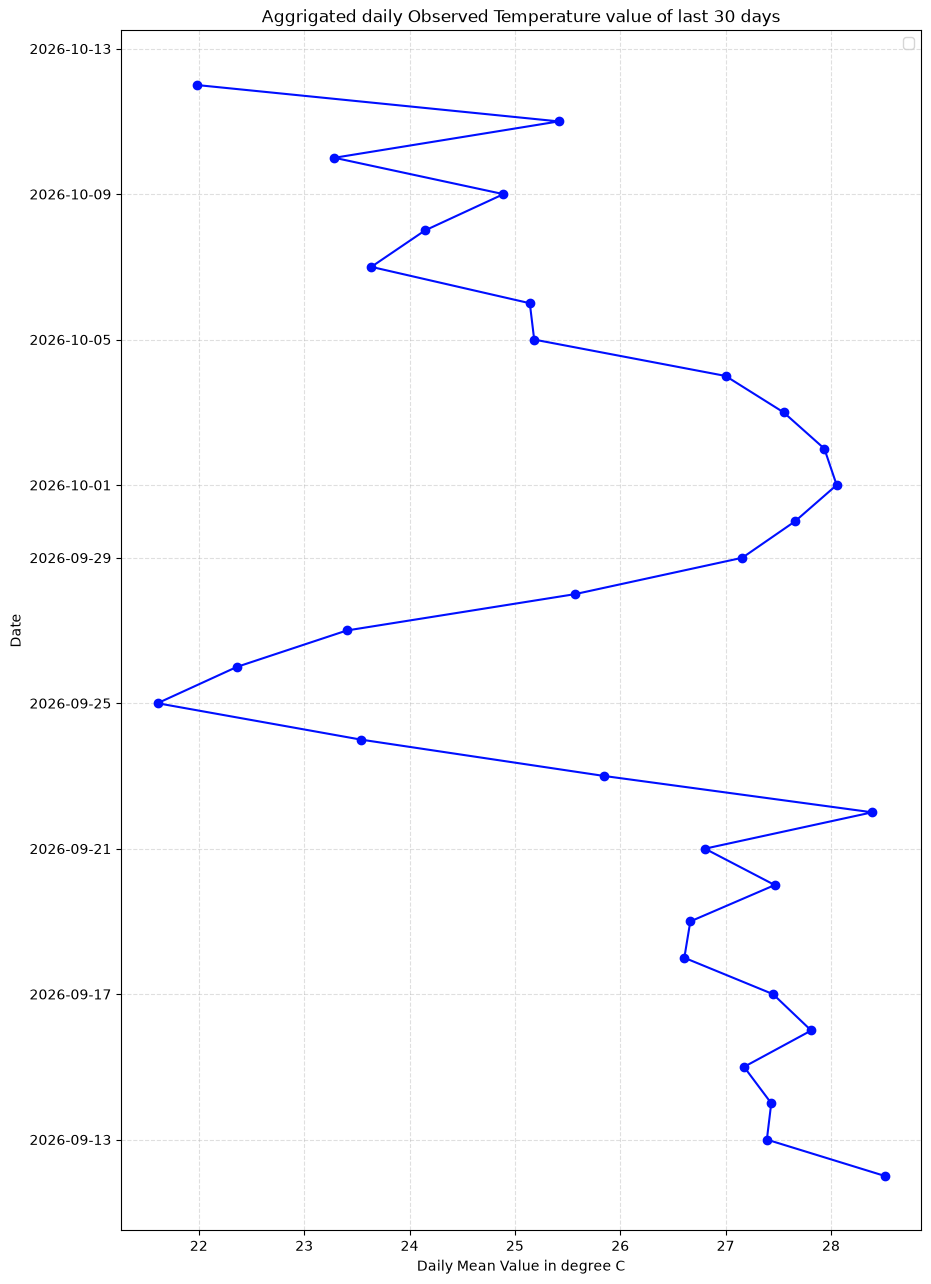

In [11]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_mean['daily_mean_value'], daily_mean['date'], color ='#000fff', marker='o')
plt.xlabel('Daily Mean Value in degree C')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed Temperature value of last 30 days")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 2. Data Analysis and Visualization of last 1 week

In [12]:
df7 = pd.read_csv('cleaned_bagdolLast7days.csv')
df7

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6230465,Bagdol,temperature,23.0,c,2026-10-05 06:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-05,06:45:00
1,6230465,Bagdol,temperature,23.9,c,2026-10-05 07:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-05,07:45:00
2,6230465,Bagdol,temperature,28.4,c,2026-10-05 08:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-05,08:45:00
3,6230465,Bagdol,temperature,27.9,c,2026-10-05 09:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-05,09:45:00
4,6230465,Bagdol,temperature,27.9,c,2026-10-05 10:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-05,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
163,6230465,Bagdol,temperature,22.5,c,2026-10-12 01:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-12,01:45:00
164,6230465,Bagdol,temperature,22.3,c,2026-10-12 02:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-12,02:45:00
165,6230465,Bagdol,temperature,22.0,c,2026-10-12 03:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-12,03:45:00
166,6230465,Bagdol,temperature,21.3,c,2026-10-12 04:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-12,04:45:00


In [13]:
# Convert the date column to a proper datetime value
df7["date"] = pd.to_datetime(df7["date"])

# Group records by date and calculate the daily mean temperature
daily_mean = (
    df7.groupby("date", as_index=False)
      .agg(
          daily_mean_value=("value", "mean"),
          observation_count=("value", "count"),
          location_id=("location_id", "first"),
          location_name=("location_name", "first"),
          parameter=("parameter", "first"),
          unit=("unit", "first"),
          timezone=("timezone", "first"),
          latitude=("latitude", "first"),
          longitude=("longitude", "first"),
          owner_name=("owner_name", "first"),
          provider=("provider", "first"),
      )
)

# Arrange columns in a clear order
daily_mean = daily_mean[
    [
        "date", "location_id", "location_name", "parameter",
        "daily_mean_value", "unit", "observation_count",
        "timezone", "latitude", "longitude", "owner_name", "provider",
    ]
]


In [14]:
daily_mean

,date,location_id,location_name,parameter,daily_mean_value,unit,observation_count,timezone,latitude,longitude,owner_name,provider
0,2026-10-05,6230465,Bagdol,temperature,25.577778,c,18,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient
1,2026-10-06,6230465,Bagdol,temperature,25.141667,c,24,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient
2,2026-10-07,6230465,Bagdol,temperature,23.637500,c,24,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient
3,2026-10-08,6230465,Bagdol,temperature,24.145833,c,24,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient
4,2026-10-09,6230465,Bagdol,temperature,24.891667,c,24,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient
5,2026-10-10,6230465,Bagdol,temperature,23.287500,c,24,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient
6,2026-10-11,6230465,Bagdol,temperature,25.416667,c,24,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient
7,2026-10-12,6230465,Bagdol,temperature,21.983333,c,6,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient


/tmp/ipykernel_10995/3647158116.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


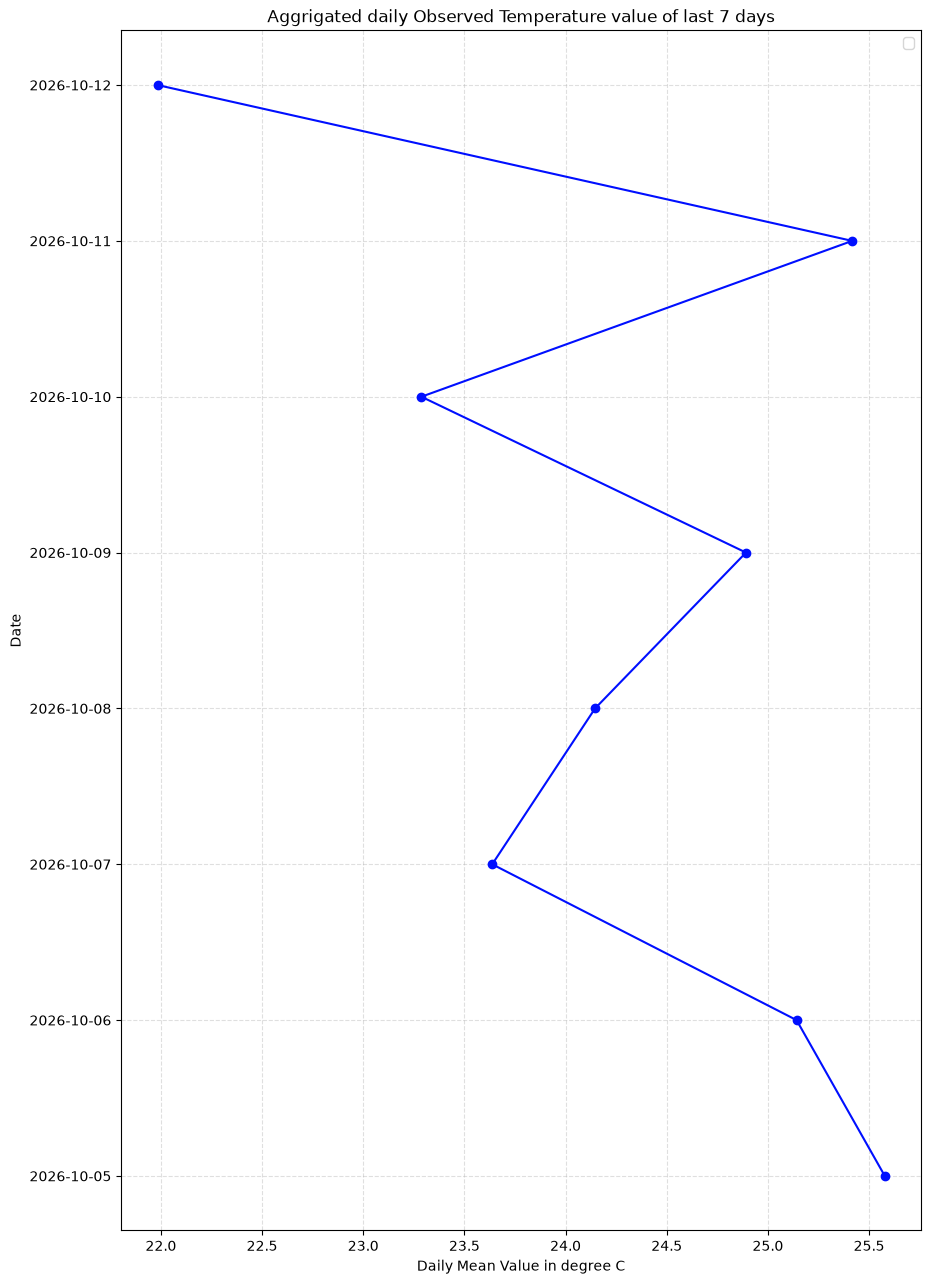

In [15]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_mean['daily_mean_value'], daily_mean['date'], color ='#000fff', marker='o')
plt.xlabel('Daily Mean Value in degree C')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed Temperature value of last 7 days")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 3. Data Analysis and Visualization of last 24 hours

In [16]:
df24 = pd.read_csv('cleaned_bagdolLast24hours.csv')
df24

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6230465,Bagdol,temperature,20.6,c,2026-10-11 06:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-11,06:45:00
1,6230465,Bagdol,temperature,21.0,c,2026-10-11 07:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-11,07:45:00
2,6230465,Bagdol,temperature,28.7,c,2026-10-11 08:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-11,08:45:00
3,6230465,Bagdol,temperature,29.7,c,2026-10-11 09:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-11,09:45:00
4,6230465,Bagdol,temperature,28.2,c,2026-10-11 10:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-11,10:45:00
5,6230465,Bagdol,temperature,29.0,c,2026-10-11 11:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-11,11:45:00
6,6230465,Bagdol,temperature,29.9,c,2026-10-11 12:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-11,12:45:00
7,6230465,Bagdol,temperature,30.5,c,2026-10-11 13:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-11,13:45:00
8,6230465,Bagdol,temperature,30.6,c,2026-10-11 14:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-11,14:45:00
9,6230465,Bagdol,temperature,30.7,c,2026-10-11 15:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-11,15:45:00


In [17]:
df24.columns

Index(['location_id', 'location_name', 'parameter', 'value', 'unit',
       'datetimeLocal', 'timezone', 'latitude', 'longitude', 'owner_name',
       'provider', 'date', 'time'],
      dtype='str')

/tmp/ipykernel_10995/4138522016.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


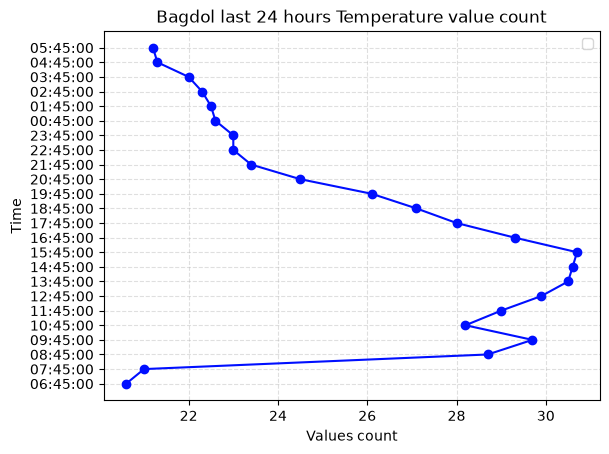

In [18]:
# Line Plot
plt.plot(df24['value'], df24['time'], color='#000fff', marker='o')
plt.xlabel('Values count')
plt.ylabel('Time')
plt.title('Bagdol last 24 hours Temperature value count')
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()